# Two-sector primitive CNOT — Stage 2: hub circuit at fixed gate density

Stage 2 of `plans/xz_noise_hub_cnot.md`, simulated with `cnot_primitive_xz.jl` (`SCHEDULE=hub`) and run with `jobs/cnot_primitive_xz_hub_full_scan.sh` (the first `k = 1` scan used a since-removed local Julia runner).

**Circuit.** The hub A is always the target. It does `N` noisy CNOT rounds with fresh partners, `k` ordinary rounds apart, with the same `k` at every size. The number of gates scales with the distance, `N = c d` with `d = L` (`c = 1, 2`), so the gate density `1/(k+1)` and the circuit's aspect ratio are fixed. Each partner gets `d` rounds, its CNOT round, and `d` rounds, then readout; A gets `d` rounds before its first CNOT and `d` after its last. Noise: depolarizing `p`, measurement `q = p`, two-qubit depolarizing `10p` at each CNOT; primitive rule mirrored per sector.

**Rates.**

- **A's final failure** `P_A(N)`: A's readout winds in either sector (`hub_failures`), and per sector X (`hub_x_failures`, which absorbs the partners' X history) and Z (`hub_z_failures`). It includes the partners' X errors that the gates copied onto A, so it is A's logical error after the circuit. A fully randomized block fails with `P_max = 15/16`, one sector with `3/4`.
- **Threshold**: finite-size crossing of `P_A(N = c d)`, the Lake-style fixed-aspect observable. `N = 2L` is an independent replica of `N = L` when `B ≈ 1`.
- **A's per-gate rate** `eps_A` from `P_A(N) = P_max [1 - B (1 - eps_A / P_max)^N]`: the single-point value at `N = L` with `B = 1`; the decay fit over `N = L, 2L` checks `B`. `Lambda_A` comes from regressing `ln eps_A` on `(L + 1)/2`. Because the circuit length grows with `L`, the `eps_A` crossing and `Lambda_A = 1` lie above the threshold: `P_A ≈ c L eps_A` is flat where `Lambda_A ≈ (L + 2)/L`.
- **Each partner** `j` has one gate, so its final failure `P_j` is already per gate. It includes A's Z errors made before gate `j` and copied onto it, so it grows with `j`; the own-fault counts (frame snapshots) remove that inheritance.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

PROJECT_DIR = next(
    (path for path in (Path.cwd(), Path.cwd().parent) if (path / "notebooks/analysis_utils.py").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Run this notebook from projects/mp-decoder or projects/mp-decoder/notebooks.")
sys.path.insert(0, str(PROJECT_DIR / "notebooks"))

from analysis_utils import (
    fit_finite_size_scaling,
    fit_lambda,
    hub_block_rates,
    load_hub_records,
    rates_as_scan,
    target_decay_grids,
    target_point_grids,
)

warnings.filterwarnings("ignore", category=RuntimeWarning)
GAP = "1"        # gap k of the scan analyzed here
MIN_L = 7        # smallest L in the main crossing fits
ASPECTS = {1: "N = L", 2: "N = 2L"}
# fit windows (p ranges) chosen for k = 1, whose threshold is near 0.53%
MAIN_WINDOW = (0.0045, 0.0065)
WINDOWS = [(0.0045, 0.0065), (0.005, 0.007), (0.004, 0.0065), (0.0045, 0.007), (0.004, 0.006), (0.0045, 0.006), (0.005, 0.0065)]
WINDOWS_Z = [(0.0045, 0.0065), (0.005, 0.007), (0.005, 0.0065), (0.0045, 0.007), (0.005, 0.008)]
EPS_MAIN_WINDOW = (0.006, 0.009)
EPS_WINDOWS = [(0.005, 0.009), (0.0055, 0.009), (0.006, 0.009), (0.0055, 0.008), (0.006, 0.008), (0.005, 0.008)]

groups = load_hub_records(PROJECT_DIR / "results/cnot_primitive_xz/hub" / f"k_{GAP}")
L_VALUES = sorted({key[1] for key in groups})
ALL_P = sorted({key[2] for key in groups})
# keep error rates where every (L, N = cL) point exists
P_VALUES = [p for p in ALL_P if all((GAP, L, p, c * L) in groups for L in L_VALUES for c in ASPECTS)]
print(f"k = {GAP}: {len(groups)} points, L = {L_VALUES}, p = {[round(100 * p, 3) for p in P_VALUES]} %")
print(f"{int(sum(g['trials'] for g in groups.values()))} trials; files per point: {sorted({g['files'] for g in groups.values()})}")

point = {c: target_point_grids(groups, GAP, L_VALUES, P_VALUES, lambda L, c=c: c * L) for c in ASPECTS}
decay = target_decay_grids(groups, GAP, L_VALUES, P_VALUES)


def show_grid(title, est, digits=4):
    rows = [f"**{title}**", "", "| L | " + " | ".join(f"{100 * p:.2f}%" for p in P_VALUES) + " |",
            "| --- |" + " --- |" * len(P_VALUES)]
    for i, L in enumerate(L_VALUES):
        rows.append(f"| {L} | " + " | ".join(f"{v:.{digits}f}" if np.isfinite(v) else "–" for v in est.values[i]) + " |")
    display(Markdown("\n".join(rows)))


def plot_grid(ax, est, title, ylabel=None):
    for i, L in enumerate(L_VALUES):
        ax.errorbar(P_VALUES, est.values[i], yerr=est.errors[i], fmt="o-", capsize=2, label=f"L = {L}")
    ax.set_yscale("log")
    ax.set_xlabel("p")
    ax.set_title(title)
    if ylabel:
        ax.set_ylabel(ylabel)


def crossing_row(grids, name, label, main_window, windows):
    # main fit (degree 2, L >= MIN_L) and the range over windows x degree 2-3 x min L 5 or 7;
    # a fit is dropped if p_c sits on a window edge or its goodness-of-fit p-value is below 0.05
    scan = rates_as_scan({name: grids[name]}, L_values=L_VALUES, p_values=P_VALUES, label=label)
    main = fit_finite_size_scaling(scan, label=label, rate_name=name, fit_p_range=main_window,
                                   min_L=MIN_L, polynomial_degree=2)
    accepted, dropped = [], 0
    for window in windows:
        for degree in (2, 3):
            for min_L in (5, 7):
                try:
                    fit = fit_finite_size_scaling(scan, label=label, rate_name=name, fit_p_range=window,
                                                  min_L=min_L, polynomial_degree=degree)
                except Exception:
                    continue
                if fit.pc <= window[0] + 1e-9 or fit.pc >= window[1] - 1e-9 or fit.p_value < 0.05:
                    dropped += 1
                    continue
                accepted.append(fit.pc)
    accepted = np.array(accepted)
    span = (f"{100 * accepted.min():.3f}-{100 * accepted.max():.3f}% ({accepted.size} fits, {dropped} dropped)"
            if accepted.size else f"no accepted fit ({dropped} dropped)")
    return (f"| {label} | {100 * main.pc:.3f} ± {100 * main.pc_error:.3f}% | "
            f"{100 * main_window[0]:.2f}-{100 * main_window[1]:.2f}% | {main.chi2:.1f}/{main.dof} ({main.p_value:.2f}) | {span} |")


CROSS_HEADER = ["| quantity | p_c (main fit) | window | chi2/dof (p-value) | range over fit choices |",
                "| --- | --- | --- | --- | --- |"]

k = 1: 100 points, L = [5, 7, 9, 11, 13], p = [0.3, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.8, 0.9] %
392155 trials; files per point: [1]


## 1. Threshold: A's failure over the whole circuit

**P_A(N = L), either sector**

| L | 0.30% | 0.40% | 0.45% | 0.50% | 0.55% | 0.60% | 0.65% | 0.70% | 0.80% | 0.90% |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5 | 0.0462 | 0.1040 | 0.1541 | 0.2023 | 0.2487 | 0.3374 | 0.3846 | 0.4588 | 0.5681 | 0.6479 |
| 7 | 0.0291 | 0.0833 | 0.1328 | 0.1872 | 0.2638 | 0.3469 | 0.4035 | 0.5055 | 0.6544 | 0.7747 |
| 9 | 0.0172 | 0.0699 | 0.1220 | 0.1876 | 0.2853 | 0.3670 | 0.4635 | 0.5502 | 0.7425 | 0.8449 |
| 11 | 0.0100 | 0.0551 | 0.1024 | 0.1762 | 0.2597 | 0.3925 | 0.4942 | 0.6207 | 0.8016 | 0.8858 |
| 13 | 0.0075 | 0.0429 | 0.0903 | 0.1619 | 0.2795 | 0.4011 | 0.5570 | 0.6829 | 0.8376 | 0.9155 |

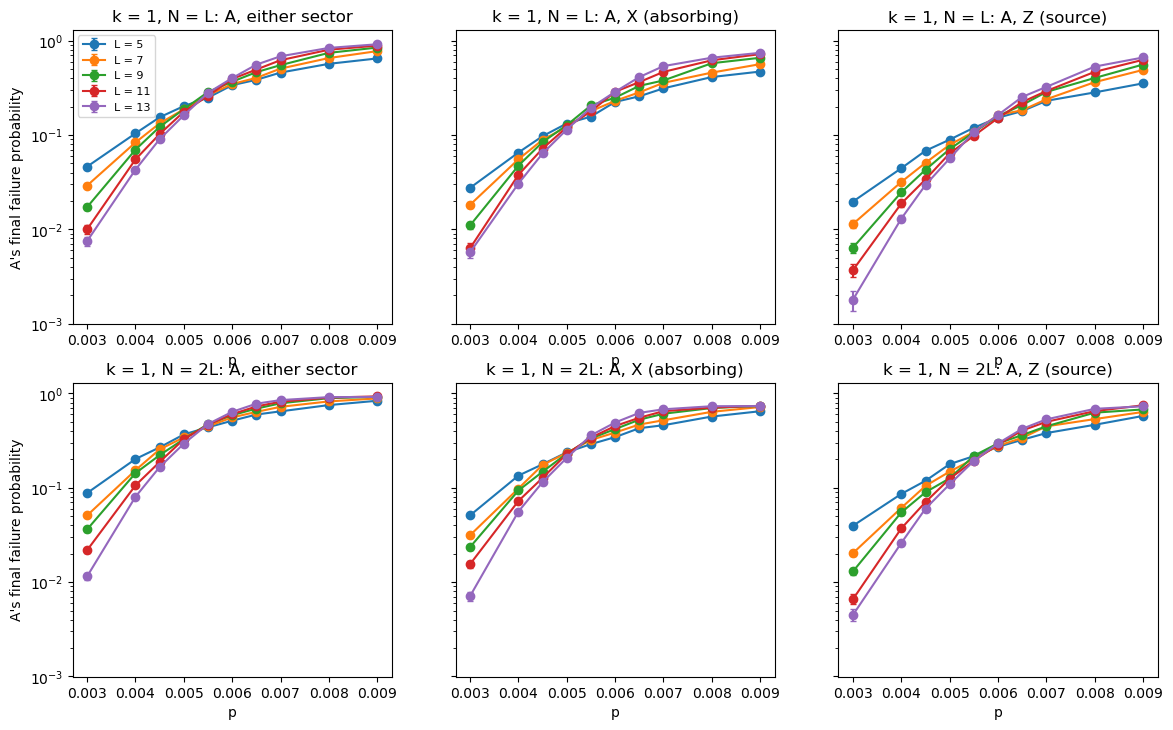

**Crossings of A's failure probability (degree 2, L >= 7 in the main fit)**

| quantity | p_c (main fit) | window | chi2/dof (p-value) | range over fit choices |
| --- | --- | --- | --- | --- |
| A, either sector, N = L | 0.533 ± 0.005% | 0.45-0.65% | 23.1/15 (0.08) | 0.531-0.542% (23 fits, 5 dropped) |
| A, X, N = L | 0.522 ± 0.006% | 0.45-0.65% | 22.6/15 (0.09) | 0.514-0.523% (12 fits, 16 dropped) |
| A, Z, N = L | 0.566 ± 0.009% | 0.45-0.65% | 12.3/15 (0.66) | 0.566-0.578% (20 fits, 0 dropped) |
| A, either sector, N = 2L | 0.532 ± 0.005% | 0.45-0.65% | 17.5/15 (0.29) | 0.529-0.538% (20 fits, 8 dropped) |
| A, X, N = 2L | 0.517 ± 0.006% | 0.45-0.65% | 14.1/15 (0.52) | 0.510-0.521% (22 fits, 6 dropped) |
| A, Z, N = 2L | 0.571 ± 0.008% | 0.45-0.65% | 12.4/15 (0.65) | 0.566-0.576% (18 fits, 2 dropped) |

- pairwise crossings, N = L: 5/7: 0.52%, 7/9: 0.50%, 9/11: 0.58%, 11/13: 0.52%
- pairwise crossings, N = 2L: 5/7: 0.54%, 7/9: 0.52%, 9/11: 0.57%, 11/13: 0.54%

In [2]:
show_grid("P_A(N = L), either sector", point[1]["P_target"])
fig, axes = plt.subplots(len(ASPECTS), 3, figsize=(14, 4.2 * len(ASPECTS)), sharey=True)
for row, (c, tag) in zip(np.atleast_2d(axes), ASPECTS.items()):
    for ax, (name, sector) in zip(row, (("P_target", "either sector"), ("P_target_x", "X (absorbing)"), ("P_target_z", "Z (source)"))):
        plot_grid(ax, point[c][name], f"k = {GAP}, {tag}: A, {sector}")
    row[0].set_ylabel("A's final failure probability")
np.atleast_2d(axes)[0, 0].legend(fontsize=8)
plt.show()

rows = [f"**Crossings of A's failure probability (degree 2, L >= {MIN_L} in the main fit)**", ""] + CROSS_HEADER
for c, tag in ASPECTS.items():
    rows += [crossing_row(point[c], "P_target", f"A, either sector, {tag}", MAIN_WINDOW, WINDOWS),
             crossing_row(point[c], "P_target_x", f"A, X, {tag}", MAIN_WINDOW, WINDOWS),
             crossing_row(point[c], "P_target_z", f"A, Z, {tag}", MAIN_WINDOW, WINDOWS_Z)]
display(Markdown("\n".join(rows)))


def pairwise(values):
    # p where consecutive sizes cross (linear interpolation)
    out = []
    for i in range(len(L_VALUES) - 1):
        diff = values[i] - values[i + 1]
        cross = next((P_VALUES[j] + diff[j] * (P_VALUES[j + 1] - P_VALUES[j]) / (diff[j] - diff[j + 1])
                      for j in range(len(P_VALUES) - 1) if diff[j] > 0 >= diff[j + 1]), np.nan)
        out.append(f"{L_VALUES[i]}/{L_VALUES[i + 1]}: {100 * cross:.2f}%")
    return ", ".join(out)


display(Markdown("\n".join(f"- pairwise crossings, {tag}: {pairwise(point[c]['P_target'].values)}" for c, tag in ASPECTS.items())))

## 2. A's per-gate rate and suppression factor

**eps_A per gate (single point at N = L)**

| L | 0.30% | 0.40% | 0.45% | 0.50% | 0.55% | 0.60% | 0.65% | 0.70% | 0.80% | 0.90% |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5 | 0.0094 | 0.0218 | 0.0331 | 0.0445 | 0.0561 | 0.0800 | 0.0939 | 0.1179 | 0.1593 | 0.1963 |
| 7 | 0.0042 | 0.0124 | 0.0202 | 0.0294 | 0.0432 | 0.0599 | 0.0724 | 0.0982 | 0.1474 | 0.2075 |
| 9 | 0.0019 | 0.0080 | 0.0144 | 0.0230 | 0.0370 | 0.0503 | 0.0684 | 0.0877 | 0.1501 | 0.2127 |
| 11 | 0.0009 | 0.0051 | 0.0098 | 0.0176 | 0.0272 | 0.0451 | 0.0617 | 0.0881 | 0.1509 | 0.2171 |
| 13 | 0.0006 | 0.0034 | 0.0073 | 0.0136 | 0.0252 | 0.0394 | 0.0628 | 0.0895 | 0.1483 | 0.2350 |

**intercept B (decay fit over N = L, 2L)**

| L | 0.30% | 0.40% | 0.45% | 0.50% | 0.55% | 0.60% | 0.65% | 0.70% | 0.80% | 0.90% |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 5 | 0.997 | 1.007 | 0.978 | 1.011 | 1.013 | 0.907 | 0.960 | 0.839 | 0.789 | 0.889 |
| 7 | 0.993 | 0.993 | 1.013 | 1.008 | 0.990 | 0.978 | 1.016 | 0.922 | 0.751 | 0.543 |
| 9 | 1.002 | 1.011 | 0.991 | 0.984 | 0.976 | 0.994 | 0.970 | 1.060 | 0.886 | 0.567 |
| 11 | 1.002 | 0.999 | 0.992 | 1.013 | 1.038 | 0.947 | 1.000 | 0.895 | 0.591 | 0.463 |
| 13 | 0.996 | 0.996 | 0.992 | 0.997 | 0.996 | 1.026 | 0.975 | 0.792 | 0.469 | 0.026 |

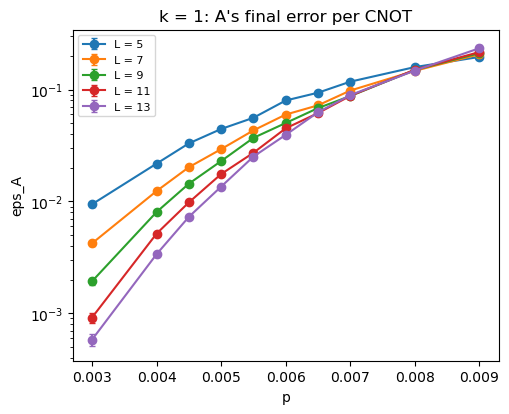

| p | Lambda_A | chi2/dof |
| --- | --- | --- |
| 0.30% | 2.09 ± 0.05 | 5.5/3 |
| 0.40% | 1.59 ± 0.02 | 5.1/3 |
| 0.45% | 1.46 ± 0.02 | 8.8/3 |
| 0.50% | 1.34 ± 0.01 | 8.1/3 |
| 0.55% | 1.23 ± 0.01 | 9.4/3 |
| 0.60% | 1.19 ± 0.01 | 11.6/3 |
| 0.65% | 1.10 ± 0.01 | 21.3/3 |
| 0.70% | 1.07 ± 0.01 | 19.6/3 |
| 0.80% | 1.01 ± 0.01 | 2.5/3 |
| 0.90% | 0.96 ± 0.01 | 0.4/3 |

`Lambda_A = 1` near p = 0.83%

| quantity | p_c (main fit) | window | chi2/dof (p-value) | range over fit choices |
| --- | --- | --- | --- | --- |
| eps_A per gate, N = L | 0.775 ± 0.022% | 0.60-0.90% | 13.8/15 (0.54) | 0.762-0.775% (12 fits, 12 dropped) |

In [3]:
show_grid("eps_A per gate (single point at N = L)", point[1]["eps_target"])
show_grid("intercept B (decay fit over N = L, 2L)", decay["B"], digits=3)
fig, ax = plt.subplots(figsize=(5.5, 4.3))
plot_grid(ax, point[1]["eps_target"], f"k = {GAP}: A's final error per CNOT", "eps_A")
ax.legend(fontsize=8)
plt.show()

rows = ["| p | Lambda_A | chi2/dof |", "| --- | --- | --- |"]
lam = []
for j, p in enumerate(P_VALUES):
    try:
        fit = fit_lambda(L_VALUES, point[1]["eps_target"].values[:, j], point[1]["eps_target"].errors[:, j])
    except ValueError:
        continue
    lam.append((p, fit.Lambda))
    rows.append(f"| {100 * p:.2f}% | {fit.Lambda:.2f} ± {fit.Lambda_error:.2f} | {fit.chi2:.1f}/{fit.dof} |")
cross = next((p0 + (1 - l0) * (p1 - p0) / (l1 - l0) for (p0, l0), (p1, l1) in zip(lam[:-1], lam[1:])
              if (l0 - 1) * (l1 - 1) <= 0 and l0 != l1), None)
rows += ["", f"`Lambda_A = 1` near p = {100 * cross:.2f}%" if cross else "`Lambda_A` does not reach 1 on this grid",
         "", *CROSS_HEADER, crossing_row(point[1], "eps_target", "eps_A per gate, N = L", EPS_MAIN_WINDOW, EPS_WINDOWS)]
display(Markdown("\n".join(rows)))

## 3. Error rate of each block

Partner profiles are pooled over `p` and divided by their mean over partners: the final readout (which carries A's Z errors from before the partner's gate) and the own faults per sector (frame snapshots).

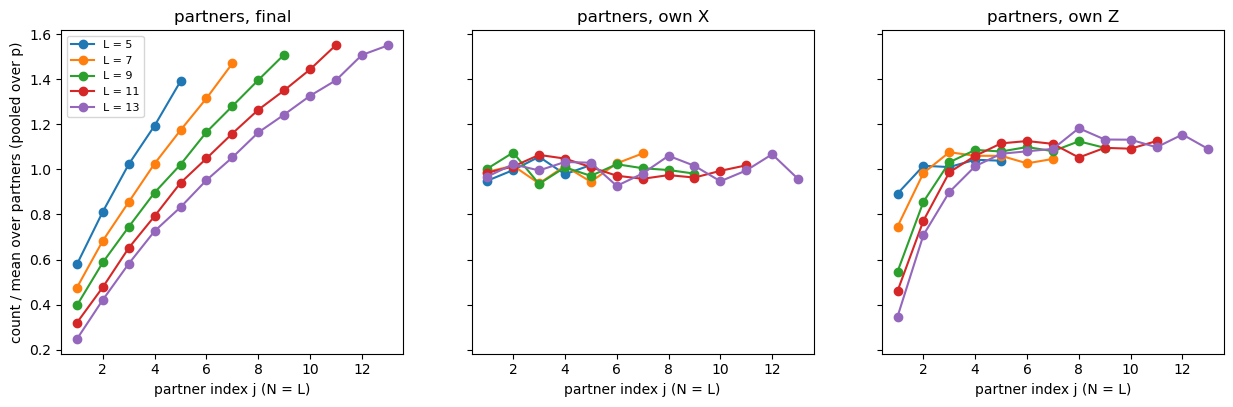

| L | N | final: first, 5th, last | own X: first, 5th, last | own Z: first, 5th, last |
| --- | --- | --- | --- | --- |
| 5 | 5 | 0.58, 1.39, 1.39 | 0.95, 1.02, 1.02 | 0.89, 1.04, 1.04 |
| 7 | 7 | 0.48, 1.17, 1.47 | 0.99, 0.94, 1.07 | 0.75, 1.06, 1.05 |
| 9 | 9 | 0.40, 1.02, 1.51 | 1.00, 0.97, 0.98 | 0.55, 1.08, 1.10 |
| 11 | 11 | 0.32, 0.94, 1.55 | 0.99, 1.01, 1.02 | 0.46, 1.12, 1.13 |
| 13 | 13 | 0.25, 0.83, 1.55 | 0.97, 1.03, 0.96 | 0.35, 1.07, 1.09 |
| 5 | 10 | 0.40, 0.98, 1.48 | 1.01, 1.02, 0.96 | 0.84, 1.06, 1.02 |
| 7 | 14 | 0.33, 0.80, 1.53 | 0.98, 0.98, 1.04 | 0.72, 1.02, 1.02 |
| 9 | 18 | 0.28, 0.70, 1.53 | 1.04, 1.02, 0.92 | 0.55, 1.03, 1.06 |
| 11 | 22 | 0.21, 0.62, 1.53 | 0.94, 0.98, 0.96 | 0.42, 0.97, 1.05 |
| 13 | 26 | 0.19, 0.56, 1.51 | 1.06, 1.05, 0.89 | 0.36, 0.98, 1.05 |

In [4]:
def profile(L, N, key):
    counts = sum(np.asarray(groups[(GAP, L, p, N)][key], dtype=float) for p in P_VALUES)
    return counts / counts.mean()


KEYS = {"final": "partner_failures_by_index", "own X": "partner_x_own_failures_by_index", "own Z": "partner_z_own_failures_by_index"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (tag, key) in zip(axes, KEYS.items()):
    for L in L_VALUES:
        ax.plot(np.arange(1, L + 1), profile(L, L, key), "o-", label=f"L = {L}")
    ax.set_xlabel("partner index j (N = L)")
    ax.set_title(f"partners, {tag}")
axes[0].set_ylabel("count / mean over partners (pooled over p)")
axes[0].legend(fontsize=8)
plt.show()

rows = ["| L | N | " + " | ".join(f"{tag}: first, 5th, last" for tag in KEYS) + " |", "| --- | --- |" + " --- |" * len(KEYS)]
for c in ASPECTS:
    for L in L_VALUES:
        N = c * L
        cells = []
        for key in KEYS.values():
            prof = profile(L, N, key)
            cells.append(f"{prof[0]:.2f}, {prof[min(4, N - 1)]:.2f}, {prof[-1]:.2f}")
        rows.append(f"| {L} | {N} | " + " | ".join(cells) + " |")
display(Markdown("\n".join(rows)))

In [5]:
SHOW_P = [0.004, 0.005]
rows = ["**Error rate of each block, N = L (final readout; own faults in brackets)**", "",
        "| L | p | A per gate | A whole circuit | partner 1 | partner mean | partner N |", "| --- | --- | --- | --- | --- | --- | --- |"]
for i, L in enumerate(L_VALUES):
    for p in SHOW_P:
        if p not in P_VALUES:
            continue
        b = hub_block_rates(groups, GAP, L, p, L)
        own = b.partners_x_own + b.partners_z_own   # own X + own Z (upper bound on own, either sector)
        rows.append(f"| {L} | {100 * p:.2f}% | {point[1]['eps_target'].values[i, P_VALUES.index(p)]:.4f} | {b.target[0]:.4f} | "
                    f"{b.partners[0]:.4f} ({own[0]:.4f}) | {b.partners.mean():.4f} ({own.mean():.4f}) | {b.partners[-1]:.4f} ({own[-1]:.4f}) |")
display(Markdown("\n".join(rows)))

tot = {key: sum(rec[key] for rec in groups.values()) for key in
       ("hub_x_failures", "hub_x_own_failures", "hub_z_failures", "hub_z_own_failures", "hub_failures", "failures",
        "trials", "cleanup_failures", "snapshot_cleanup_failures")}
worst = max(groups.items(), key=lambda kv: kv[1]["cleanup_failures"] / kv[1]["trials"])
display(Markdown(
    f"- A's final/own failures: X {tot['hub_x_failures'] / tot['hub_x_own_failures']:.4f}, "
    f"Z {tot['hub_z_failures'] / tot['hub_z_own_failures']:.4f}; A has {tot['hub_failures'] / tot['failures']:.2f} of the failed trials.\n"
    f"- Readout cleanup failed in {int(tot['cleanup_failures'])} of {int(tot['trials'])} trials; the largest rate is "
    f"{worst[1]['cleanup_failures'] / worst[1]['trials']:.3f} at L = {worst[0][1]}, p = {100 * worst[0][2]:.2f}%, N = {worst[0][3]}.\n"
    f"- Snapshot cleanup failed {int(tot['snapshot_cleanup_failures'])} times."
))

**Error rate of each block, N = L (final readout; own faults in brackets)**

| L | p | A per gate | A whole circuit | partner 1 | partner mean | partner N |
| --- | --- | --- | --- | --- | --- | --- |
| 5 | 0.40% | 0.0218 | 0.1040 | 0.0223 (0.0230) | 0.0410 (0.0260) | 0.0599 (0.0287) |
| 5 | 0.50% | 0.0445 | 0.2023 | 0.0430 (0.0458) | 0.0828 (0.0520) | 0.1219 (0.0586) |
| 7 | 0.40% | 0.0124 | 0.0833 | 0.0119 (0.0122) | 0.0262 (0.0145) | 0.0410 (0.0156) |
| 7 | 0.50% | 0.0294 | 0.1872 | 0.0230 (0.0236) | 0.0630 (0.0350) | 0.0943 (0.0341) |
| 9 | 0.40% | 0.0080 | 0.0699 | 0.0058 (0.0059) | 0.0176 (0.0098) | 0.0292 (0.0101) |
| 9 | 0.50% | 0.0230 | 0.1876 | 0.0172 (0.0177) | 0.0522 (0.0290) | 0.0874 (0.0327) |
| 11 | 0.40% | 0.0051 | 0.0551 | 0.0028 (0.0028) | 0.0119 (0.0059) | 0.0207 (0.0073) |
| 11 | 0.50% | 0.0176 | 0.1762 | 0.0114 (0.0116) | 0.0395 (0.0210) | 0.0694 (0.0249) |
| 13 | 0.40% | 0.0034 | 0.0429 | 0.0017 (0.0017) | 0.0083 (0.0038) | 0.0148 (0.0041) |
| 13 | 0.50% | 0.0136 | 0.1619 | 0.0079 (0.0081) | 0.0388 (0.0169) | 0.0658 (0.0180) |

- A's final/own failures: X 1.0034, Z 1.0000; A has 0.68 of the failed trials.
- Readout cleanup failed in 552 of 392155 trials; the largest rate is 0.034 at L = 9, p = 0.90%, N = 18.
- Snapshot cleanup failed 2011 times.

## Findings (`k = 1`, first local scan)

Scan: 100 points and 3.9e5 trials (local, 8 threads, 1.8 h); `L = 5-13`, `p = 0.3-0.9%`, `N = L` and `2L`; each point capped at 1500 failed trials or 10^4 trials (stopping on any block, before `STOP_COUNT=hub` existed).

**Threshold (A's final failure).**

- `P_A` crosses at 0.533(5)% for `N = L` and 0.532(5)% for `N = 2L` (window [0.45, 0.65]%, `L >= 7`, degree 2); 0.53-0.54% over fit choices.
- That is 0.30 of the memory threshold (1.77%, Stage 1).
- A's X sector (absorbing) crosses lowest, at 0.51-0.52%; its Z sector at 0.57%.
- Pairwise crossings are 0.50-0.58%. `L = 9` does relatively worse at both aspect ratios, and is also where cleanup failures concentrate.

**Per-gate rate.**

- `eps_A` at `p = 0.4%` falls from 0.022 (`L = 5`) to 0.0034 (`L = 13`).
- `Lambda_A` = 2.09, 1.59, 1.34, 1.19 at `p` = 0.3, 0.4, 0.5, 0.6%. It reaches 1 near 0.83%, and `eps_A` crosses at 0.775(22)%. Both are above the threshold, as expected for a circuit whose length grows with `L`.
- `B` is 0.98-1.04 for `p <= 0.55%`, so the single-point rate at `N = L` is justified.

**Each block.**

- A's final failures equal its own faults (final/own 1.003 in X, 1.000 in Z). A has 0.68 of the failed trials.
- Partners:
  - final failure rises with the index, from 0.19-0.58 to about 1.5 of the mean, because partner `j` carries A's Z errors from before gate `j`;
  - own X is flat;
  - own Z rises over the first 4-5 gates (the first partner is at 0.35-0.9 of the plateau, lower at larger `L`) and is flat afterwards, at both `N = L` and `2L`. A is therefore stationary after a short warm-up;
  - a partner's own rate (X + Z) at `p = 0.4%` falls from 0.026 (`L = 5`) to 0.0038 (`L = 13`), close to A's per-gate rate.
- Cleanup: readout cleanup failed in 552 trials (largest 3.4% at `L = 9`, `p = 0.9%`, `N = 2L`), snapshot cleanup 2011 times.